# Sistema de enrutamiento para tiendas con Búsqueda Tabú

Optimización de las rutas de 10 CEDIS hacia 90 tiendas en Culiacán, Sinaloa.

Se cargan los tres archivos de Excel (tiendas, distancias y costos) y se revisan sus dimensiones.

In [ ]:
import numpy as np
import pandas as pd

# Lectura de los archivos Excel
df_tiendas = pd.read_excel('./chuy_datasets/datos_distribucion_tiendas.xlsx')
df_distancias = pd.read_excel('./chuy_datasets/matriz_distancias.xlsx')
df_costos = pd.read_excel('./chuy_datasets/matriz_costos_combustible.xlsx')

# Conversión a matrices de NumPy
matriz_dist = df_distancias.to_numpy()
matriz_costo = df_costos.to_numpy()

print(f'La matriz de distancias tiene {matriz_dist.shape[0]} filas y {matriz_dist.shape[1]} columnas.')
print(f'La matriz de costos tiene {matriz_costo.shape[0]} filas y {matriz_costo.shape[1]} columnas.')
conteo = df_tiendas['Tipo'].value_counts()
print(f"Hay {conteo['Centro de Distribución']} centros de distribución y {conteo['Tienda']} tiendas.")

print('\nPrimeras filas y columnas de la matriz de distancias (km):')
display(df_distancias.iloc[:5, :5])

La matriz de distancias tiene 100 filas y 100 columnas.
La matriz de costos tiene 100 filas y 100 columnas.
Hay 10 centros de distribución y 90 tiendas.

Primeras filas y columnas de la matriz de distancias (km):


,Nodo_1,Nodo_2,Nodo_3,Nodo_4,Nodo_5
0,0.000000,22.027423,16.103521,15.988868,12.228125
1,22.027423,0.000000,13.763643,11.832109,19.517618
2,16.103521,13.763643,0.000000,18.401809,6.880980
3,15.988868,11.832109,18.401809,0.000000,20.688967
4,12.228125,19.517618,6.880980,20.688967,0.000000


Se verifica que no haya datos faltantes.

In [2]:
nulos_tiendas = df_tiendas[['Tipo', 'Nombre', 'Latitud_WGS84', 'Longitud_WGS84']].isnull().sum().sum()
nulos_dist = df_distancias.isnull().sum().sum()
nulos_costos = df_costos.isnull().sum().sum()

faltantes = pd.Series({'Tabla de tiendas': nulos_tiendas, 'Distancias': nulos_dist, 'Costos': nulos_costos},
                      name='Valores nulos')
display(faltantes.to_frame())

if nulos_tiendas + nulos_dist + nulos_costos == 0:
    print('No hay datos faltantes, se puede continuar.')

,Valores nulos
Tabla de tiendas,0
Distancias,0
Costos,0


No hay datos faltantes, se puede continuar.


Se separan los 10 CEDIS (índices 0 a 9) de las 90 tiendas (índices 10 a 99).

In [3]:
cedis_df = df_tiendas[df_tiendas['Tipo'] == 'Centro de Distribución']
tiendas_df = df_tiendas[df_tiendas['Tipo'] == 'Tienda']

cedis_indices = list(range(0, 10))
tiendas_indices = list(range(10, 100))

display(cedis_df)
print(f'Se trabajará con {len(cedis_indices)} CEDIS y {len(tiendas_indices)} tiendas, '
      f'es decir, {len(tiendas_indices) // len(cedis_indices)} tiendas por cada CEDIS.')

,Tipo,Nombre,Latitud_WGS84,Longitud_WGS84,Capacidad_Venta,Capacidad_Almacenamiento,Nivel_Tienda
0,Centro de Distribución,Centro de Distribución 1,24.774908,-107.309857,13648,11639,NaN
1,Centro de Distribución,Centro de Distribución 2,24.846399,-107.380268,19012,26049,NaN
2,Centro de Distribución,Centro de Distribución 3,24.731204,-107.468801,17314,19144,NaN
3,Centro de Distribución,Centro de Distribución 4,24.711617,-107.326765,13358,45741,NaN
4,Centro de Distribución,Centro de Distribución 5,24.820223,-107.358385,12848,48698,NaN
5,Centro de Distribución,Centro de Distribución 6,24.704117,-107.306018,23825,12082,NaN
6,Centro de Distribución,Centro de Distribución 7,24.866489,-107.457532,10976,16140,NaN
7,Centro de Distribución,Centro de Distribución 8,24.736365,-107.463319,17164,25247,NaN
8,Centro de Distribución,Centro de Distribución 9,24.760848,-107.395049,26559,49453,NaN
9,Centro de Distribución,Centro de Distribución 10,24.786389,-107.441754,10869,46781,NaN


Se trabajará con 10 CEDIS y 90 tiendas, es decir, 9 tiendas por cada CEDIS.


Se calculan la distancia y el costo mínimo, máximo y promedio. También se ve que el combustible cuesta 0.15 por km en todos los tramos.

In [4]:
dist_sin_ceros = matriz_dist[matriz_dist > 0]
costos_sin_ceros = matriz_costo[matriz_costo > 0]

resumen = pd.DataFrame({
    'Distancia (km)': [np.min(dist_sin_ceros), np.max(dist_sin_ceros), np.mean(dist_sin_ceros)],
    'Costo combustible': [np.min(costos_sin_ceros), np.max(costos_sin_ceros), np.mean(costos_sin_ceros)],
}, index=['Mínimo', 'Máximo', 'Promedio'])
display(resumen.round(2))

# Relación entre costo y distancia
costo_por_km = costos_sin_ceros / dist_sin_ceros
print(f'El costo de combustible por km va de {costo_por_km.min():.2f} a {costo_por_km.max():.2f}, '
      'o sea que siempre es el mismo.')

,Distancia (km),Costo combustible
Mínimo,0.12,0.02
Máximo,27.35,4.10
Promedio,11.38,1.71


El costo de combustible por km va de 0.15 a 0.15, o sea que siempre es el mismo.


Se normalizan las matrices entre 0 y 1 y se combinan con los pesos W1 = 0.25 (distancia) y W2 = 0.75 (combustible).

In [5]:
def normalizar(matriz):
    """Escala los valores de la matriz al rango [0, 1]."""
    return (matriz - matriz.min()) / (matriz.max() - matriz.min())

W1 = 0.25   # peso de la distancia
W2 = 0.75   # peso del combustible

dist_norm = normalizar(matriz_dist)
costo_norm = normalizar(matriz_costo)

# Matriz combinada que usará la búsqueda tabú
matriz_combinada = W1 * dist_norm + W2 * costo_norm

print(f'La matriz combinada quedó entre {matriz_combinada.min():.2f} y {matriz_combinada.max():.2f}.')

La matriz combinada quedó entre 0.00 y 1.00.


Función objetivo: suma los tramos de la ruta CEDIS → tiendas → CEDIS.

In [6]:
def calcular_costo_ruta(ruta, matriz):
    """Calcula el costo de una ruta cerrada: CEDIS -> tiendas -> CEDIS."""
    costo = 0
    # Tramos desde el CEDIS y entre tiendas (k = 0 a 8)
    for k in range(len(ruta) - 1):
        costo += matriz[ruta[k]][ruta[k + 1]]
    # Regreso de la última tienda al CEDIS
    costo += matriz[ruta[-1]][ruta[0]]
    return costo


def calcular_costo_total(rutas, matriz):
    """Suma el costo de las 10 rutas."""
    total = 0
    for ruta in rutas.values():
        total += calcular_costo_ruta(ruta, matriz)
    return total

Asignación codiciosa secuencial: cada tienda va al CEDIS más cercano que todavía tenga lugar (máximo 9 tiendas).

In [7]:
def asignar_tiendas(matriz, cedis, tiendas, capacidad=9):
    """Asigna cada tienda al CEDIS más cercano que tenga lugar disponible."""
    parejas = []
    for t in tiendas:
        for c in cedis:
            parejas.append((matriz[t][c], t, c))
    parejas.sort()   # de menor a mayor distancia

    asignacion = {c: [] for c in cedis}
    asignadas = set()
    for distancia, t, c in parejas:
        if t not in asignadas and len(asignacion[c]) < capacidad:
            asignacion[c].append(t)
            asignadas.add(t)
    return asignacion


asignacion = asignar_tiendas(matriz_dist, cedis_indices, tiendas_indices)

print('Tiendas asignadas a cada CEDIS:')
for c, ts in asignacion.items():
    nombres = [f'T{t - 9}' for t in sorted(ts)]   # el índice 10 es la Tienda 1
    print(f'  CEDIS {c + 1} -> {", ".join(nombres)}')

Tiendas asignadas a cada CEDIS:
  CEDIS 1 -> T5, T30, T34, T38, T45, T49, T67, T85, T90
  CEDIS 2 -> T1, T6, T20, T21, T47, T52, T69, T74, T81
  CEDIS 3 -> T3, T17, T26, T32, T78, T79, T80, T83, T88
  CEDIS 4 -> T35, T37, T43, T51, T57, T59, T75, T82, T84
  CEDIS 5 -> T11, T13, T41, T53, T65, T66, T70, T71, T86
  CEDIS 6 -> T9, T10, T15, T16, T18, T33, T62, T76, T87
  CEDIS 7 -> T2, T14, T27, T31, T48, T54, T60, T73, T89
  CEDIS 8 -> T7, T22, T24, T25, T50, T55, T56, T64, T77
  CEDIS 9 -> T8, T19, T29, T36, T40, T42, T58, T68, T72
  CEDIS 10 -> T4, T12, T23, T28, T39, T44, T46, T61, T63


Se arma la solución inicial (tiendas en orden de lista) y la del vecino más cercano para compararlas.

In [8]:
# Solución inicial: CEDIS + tiendas en orden de lista
rutas_iniciales = {}
for c, ts in asignacion.items():
    rutas_iniciales[c] = [c] + sorted(ts)


def vecino_mas_cercano(cedis, tiendas, matriz):
    """Construye una ruta yendo siempre a la tienda más cercana que falte."""
    ruta = [cedis]
    pendientes = list(tiendas)
    while pendientes:
        actual = ruta[-1]
        siguiente = min(pendientes, key=lambda t: matriz[actual][t])
        ruta.append(siguiente)
        pendientes.remove(siguiente)
    return ruta


rutas_vmc = {}
for c, ts in asignacion.items():
    rutas_vmc[c] = vecino_mas_cercano(c, sorted(ts), matriz_combinada)

distancia_inicial = calcular_costo_total(rutas_iniciales, matriz_dist)
costo_inicial = calcular_costo_total(rutas_iniciales, matriz_costo)
distancia_vmc = calcular_costo_total(rutas_vmc, matriz_dist)
costo_vmc = calcular_costo_total(rutas_vmc, matriz_costo)

print(f'Solución inicial: {distancia_inicial:,.2f} km recorridos y {costo_inicial:,.2f} de combustible.')
print(f'Vecino más cercano: {distancia_vmc:,.2f} km recorridos y {costo_vmc:,.2f} de combustible.')

Solución inicial: 569.87 km recorridos y 85.48 de combustible.
Vecino más cercano: 285.83 km recorridos y 42.87 de combustible.


Los vecinos se generan intercambiando dos tiendas de la ruta; el CEDIS no se mueve.

In [9]:
def generar_vecinos(ruta):
    """Regresa todos los vecinos intercambiando dos tiendas (el CEDIS no se mueve)."""
    vecinos = []
    for i in range(1, len(ruta) - 1):
        for j in range(i + 1, len(ruta)):
            vecino = ruta.copy()
            vecino[i], vecino[j] = vecino[j], vecino[i]
            movimiento = (min(ruta[i], ruta[j]), max(ruta[i], ruta[j]))  # par de tiendas intercambiadas
            vecinos.append((vecino, movimiento))
    return vecinos

print(f'La ruta del CEDIS 1 tiene {len(generar_vecinos(rutas_iniciales[0]))} vecinos posibles.')

La ruta del CEDIS 1 tiene 36 vecinos posibles.


Función para comprobar que las rutas cumplen las restricciones.

In [10]:
def validar_rutas(rutas, asignacion):
    """Verifica que todas las rutas sean válidas."""
    todas_las_tiendas = []
    for c, ruta in rutas.items():
        if ruta[0] != c:                                  # debe iniciar en su CEDIS
            return False
        if sorted(ruta[1:]) != sorted(asignacion[c]):     # debe tener sus 9 tiendas
            return False
        if len(set(ruta)) != len(ruta):                   # sin repetidos
            return False
        todas_las_tiendas += ruta[1:]
    return len(set(todas_las_tiendas)) == 90             # las 90 tiendas se visitan

if validar_rutas(rutas_iniciales, asignacion):
    print('La solución inicial cumple con todas las restricciones.')
else:
    print('La solución inicial NO cumple con las restricciones.')

La solución inicial cumple con todas las restricciones.


Búsqueda tabú: elige el mejor vecino que no esté en la lista tabú (de 10 movimientos), con criterio de aspiración y paro tras 50 iteraciones sin mejora.

In [11]:
def busqueda_tabu(ruta_inicial, matriz, tam_lista_tabu=10, max_iter=200, max_sin_mejora=50):
    """Búsqueda tabú para una ruta. Regresa la mejor ruta, su costo y el historial de costos."""
    ruta_actual = ruta_inicial.copy()
    mejor_ruta = ruta_inicial.copy()
    mejor_costo = calcular_costo_ruta(mejor_ruta, matriz)

    lista_tabu = []
    historial = [mejor_costo]
    sin_mejora = 0

    for iteracion in range(max_iter):
        mejor_vecino = None
        costo_mejor_vecino = float('inf')
        movimiento_elegido = None

        # Revisar todos los vecinos
        for vecino, movimiento in generar_vecinos(ruta_actual):
            costo_vecino = calcular_costo_ruta(vecino, matriz)
            es_tabu = movimiento in lista_tabu
            # Se acepta si no es tabú, o si es tabú pero mejora la mejor solución (aspiración)
            if (not es_tabu) or (costo_vecino < mejor_costo):
                if costo_vecino < costo_mejor_vecino:
                    mejor_vecino = vecino
                    costo_mejor_vecino = costo_vecino
                    movimiento_elegido = movimiento

        if mejor_vecino is None:   # todos los movimientos son tabú
            break

        # Moverse al mejor vecino y actualizar la lista tabú
        ruta_actual = mejor_vecino
        lista_tabu.append(movimiento_elegido)
        if len(lista_tabu) > tam_lista_tabu:
            lista_tabu.pop(0)   # se elimina el movimiento más antiguo

        # Actualizar la mejor solución
        if costo_mejor_vecino < mejor_costo:
            mejor_ruta = mejor_vecino.copy()
            mejor_costo = costo_mejor_vecino
            sin_mejora = 0
        else:
            sin_mejora += 1

        historial.append(costo_mejor_vecino)
        if sin_mejora >= max_sin_mejora:
            break

    return mejor_ruta, mejor_costo, historial

Se ejecuta la búsqueda tabú en las 10 rutas y se mide el tiempo.

In [12]:
import time

TAM_LISTA_TABU = 10
MAX_ITER = 200
MAX_SIN_MEJORA = 50

rutas_optimizadas = {}
historiales = {}

inicio = time.perf_counter()
for c, ruta in rutas_iniciales.items():
    mejor_ruta, mejor_costo, historial = busqueda_tabu(ruta, matriz_combinada, TAM_LISTA_TABU, MAX_ITER, MAX_SIN_MEJORA)
    rutas_optimizadas[c] = mejor_ruta
    historiales[c] = historial
tiempo_ejecucion = time.perf_counter() - inicio

distancia_tabu = calcular_costo_total(rutas_optimizadas, matriz_dist)
costo_tabu = calcular_costo_total(rutas_optimizadas, matriz_costo)

for c, ruta in rutas_optimizadas.items():
    texto = ' -> '.join(f'T{n - 9}' for n in ruta[1:])
    print(f'Ruta del CEDIS {c + 1} ({calcular_costo_ruta(ruta, matriz_dist):.2f} km): {texto}')

print(f'\nCon búsqueda tabú se recorren {distancia_tabu:,.2f} km en total, con un costo de combustible '
      f'de {costo_tabu:,.2f}. El cálculo tardó {tiempo_ejecucion:.4f} segundos.')

Ruta del CEDIS 1 (29.05 km): T45 -> T30 -> T49 -> T34 -> T90 -> T5 -> T67 -> T85 -> T38
Ruta del CEDIS 2 (22.43 km): T69 -> T74 -> T81 -> T47 -> T20 -> T21 -> T52 -> T6 -> T1
Ruta del CEDIS 3 (56.72 km): T26 -> T79 -> T88 -> T78 -> T3 -> T83 -> T32 -> T80 -> T17
Ruta del CEDIS 4 (17.71 km): T37 -> T59 -> T57 -> T82 -> T51 -> T43 -> T75 -> T84 -> T35
Ruta del CEDIS 5 (20.68 km): T66 -> T11 -> T65 -> T70 -> T13 -> T53 -> T41 -> T86 -> T71
Ruta del CEDIS 6 (17.09 km): T16 -> T10 -> T18 -> T33 -> T9 -> T76 -> T62 -> T15 -> T87
Ruta del CEDIS 7 (17.74 km): T60 -> T14 -> T54 -> T89 -> T27 -> T2 -> T48 -> T31 -> T73
Ruta del CEDIS 8 (33.46 km): T7 -> T22 -> T25 -> T56 -> T77 -> T50 -> T55 -> T64 -> T24
Ruta del CEDIS 9 (21.19 km): T8 -> T68 -> T42 -> T40 -> T36 -> T19 -> T29 -> T72 -> T58
Ruta del CEDIS 10 (33.73 km): T61 -> T28 -> T23 -> T12 -> T44 -> T39 -> T63 -> T46 -> T4

Con búsqueda tabú se recorren 269.81 km en total, con un costo de combustible de 40.47. El cálculo tardó 0.0482 segun

Se comparan los resultados con la línea base y el vecino más cercano.

In [13]:
if validar_rutas(rutas_optimizadas, asignacion):
    print('La solución optimizada cumple con todas las restricciones.')

tabla_resultados = pd.DataFrame({
    'Método': ['Línea base (sin optimizar)', 'Vecino más cercano', 'Búsqueda tabú'],
    'Distancia (km)': [distancia_inicial, distancia_vmc, distancia_tabu],
    'Costo combustible': [costo_inicial, costo_vmc, costo_tabu],
})
tabla_resultados['Tiempo de manejo (h)'] = tabla_resultados['Distancia (km)'] / 30   # velocidad promedio 30 km/h
display(tabla_resultados.round(2))

# Detalle por ruta
detalle = pd.DataFrame({
    'CEDIS': [f'CEDIS {c + 1}' for c in rutas_iniciales],
    'Km inicial': [calcular_costo_ruta(r, matriz_dist) for r in rutas_iniciales.values()],
    'Km tabú': [calcular_costo_ruta(r, matriz_dist) for r in rutas_optimizadas.values()],
})
detalle['Mejora (%)'] = (detalle['Km inicial'] - detalle['Km tabú']) / detalle['Km inicial'] * 100
display(detalle.round(2))

La solución optimizada cumple con todas las restricciones.


,Método,Distancia (km),Costo combustible,Tiempo de manejo (h)
0,Línea base (sin optimizar),569.87,85.48,19.00
1,Vecino más cercano,285.83,42.87,9.53
2,Búsqueda tabú,269.81,40.47,8.99


,CEDIS,Km inicial,Km tabú,Mejora (%)
0,CEDIS 1,57.12,29.05,49.13
1,CEDIS 2,37.08,22.43,39.50
2,CEDIS 3,139.35,56.72,59.30
3,CEDIS 4,41.23,17.71,57.04
4,CEDIS 5,37.39,20.68,44.69
5,CEDIS 6,26.72,17.09,36.05
6,CEDIS 7,34.11,17.74,48.00
7,CEDIS 8,83.55,33.46,59.96
8,CEDIS 9,40.36,21.19,47.48
9,CEDIS 10,72.95,33.73,53.76


Curva de convergencia de tres rutas.

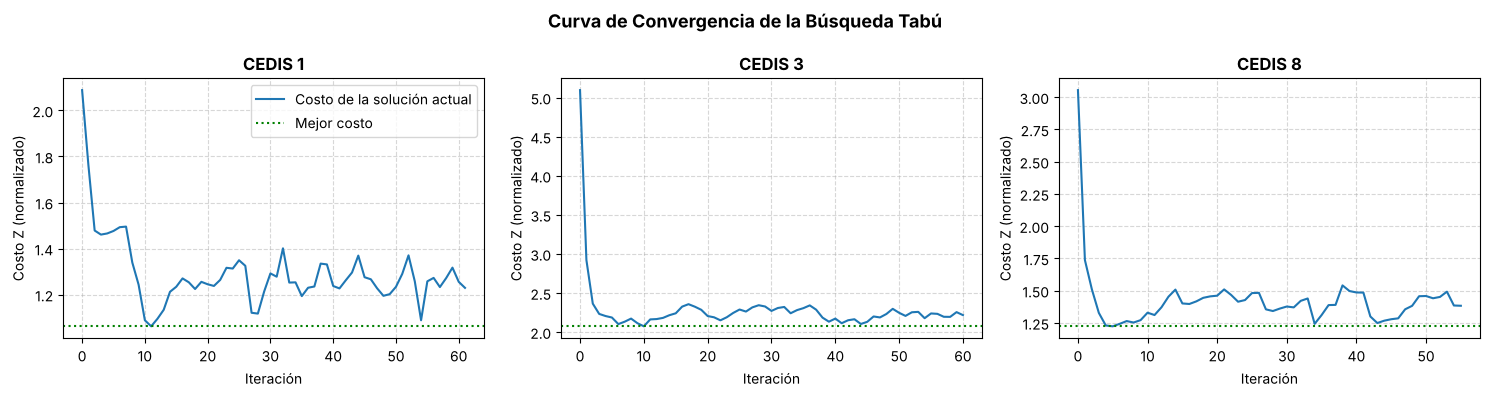

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, [0, 2, 7]):
    ax.plot(historiales[c], color='#1f77b4', linewidth=1.5, label='Costo de la solución actual')
    ax.axhline(y=min(historiales[c]), color='green', linestyle=':', label='Mejor costo')
    ax.set_title(f'CEDIS {c + 1}', fontweight='bold')
    ax.set_xlabel('Iteración')
    ax.set_ylabel('Costo Z (normalizado)')
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].legend()
plt.suptitle('Curva de Convergencia de la Búsqueda Tabú', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('./Datasets/convergencia_tabu.png', dpi=150)
plt.show()

Se calcula el ahorro porcentual y se grafica la distancia por ruta antes y después.

Se ahorraron 300.06 km (52.65%) y 45.01 de combustible (52.65%).
Comparado con el vecino más cercano, la búsqueda tabú recorre 5.60% menos.


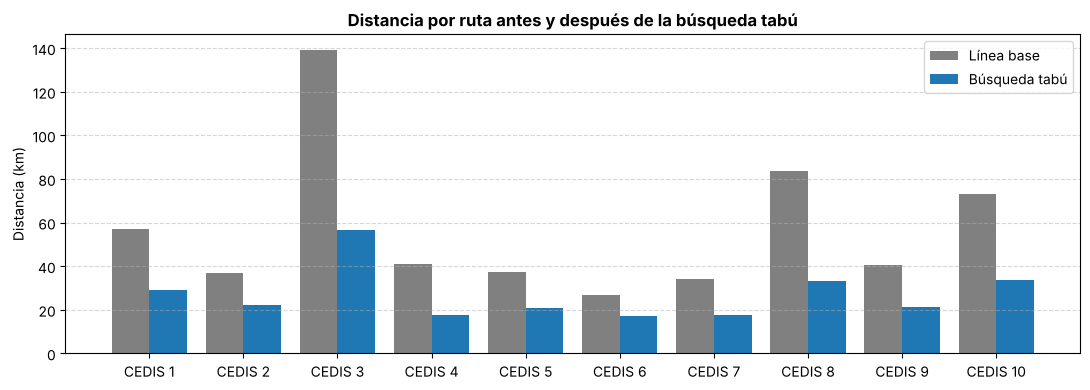

In [15]:
ahorro_km = distancia_inicial - distancia_tabu
ahorro_costo = costo_inicial - costo_tabu
pct_km = ahorro_km / distancia_inicial * 100
pct_costo = ahorro_costo / costo_inicial * 100
pct_vs_vmc = (distancia_vmc - distancia_tabu) / distancia_vmc * 100

print(f'Se ahorraron {ahorro_km:,.2f} km ({pct_km:.2f}%) y {ahorro_costo:,.2f} de combustible ({pct_costo:.2f}%).')
print(f'Comparado con el vecino más cercano, la búsqueda tabú recorre {pct_vs_vmc:.2f}% menos.')

# Gráfica de barras por ruta
x = np.arange(10)
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, detalle['Km inicial'], width=0.4, color='gray', label='Línea base')
plt.bar(x + 0.2, detalle['Km tabú'], width=0.4, color='#1f77b4', label='Búsqueda tabú')
plt.xticks(x, detalle['CEDIS'])
plt.ylabel('Distancia (km)')
plt.title('Distancia por ruta antes y después de la búsqueda tabú', fontweight='bold')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('./Datasets/distancia_por_ruta.png', dpi=150)
plt.show()

Se prueba la búsqueda con distintos tamaños de lista tabú, partiendo de 20 soluciones aleatorias.

In [16]:
import random

resultados_tam = []
for tam in [1, 3, 5, 10, 15]:
    random.seed(42)
    distancias = []
    for repeticion in range(20):
        total = 0
        for c, ts in asignacion.items():
            ruta_aleatoria = [c] + random.sample(ts, len(ts))
            mejor_ruta, _, _ = busqueda_tabu(ruta_aleatoria, matriz_combinada, tam, MAX_ITER, MAX_SIN_MEJORA)
            total += calcular_costo_ruta(mejor_ruta, matriz_dist)
        distancias.append(total)
    resultados_tam.append({'Tamaño lista tabú': tam,
                           'Distancia promedio (km)': np.mean(distancias),
                           'Peor resultado (km)': np.max(distancias)})

tabla_tam = pd.DataFrame(resultados_tam)
display(tabla_tam.round(2))

,Tamaño lista tabú,Distancia promedio (km),Peor resultado (km)
0,1,282.67,317.38
1,3,274.74,282.83
2,5,272.58,276.09
3,10,270.16,273.94
4,15,270.45,273.94


Ubicación de los CEDIS y las tiendas en Culiacán.

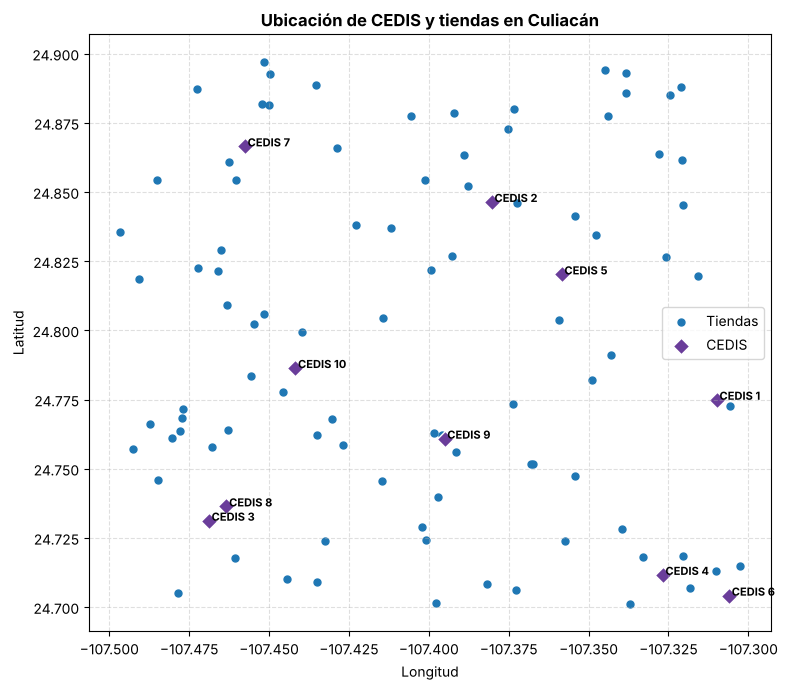

In [17]:
plt.figure(figsize=(8, 7))
plt.scatter(tiendas_df['Longitud_WGS84'], tiendas_df['Latitud_WGS84'], c='#1f77b4', s=25, label='Tiendas')
plt.scatter(cedis_df['Longitud_WGS84'], cedis_df['Latitud_WGS84'], c='#6a3d9a', marker='D', s=70, edgecolors='white', label='CEDIS')
for idx, row in cedis_df.iterrows():
    plt.annotate(f' CEDIS {idx + 1}', (row['Longitud_WGS84'], row['Latitud_WGS84']), fontsize=8, fontweight='bold')
plt.title('Ubicación de CEDIS y tiendas en Culiacán', fontweight='bold')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('./Datasets/mapa_puntos.png', dpi=150)
plt.show()

Para dibujar las rutas sobre el mapa se usan distancias reales entre coordenadas (Haversine). Se arma una solución al azar y otra resuelta con búsqueda tabú más intercambio de tiendas entre rutas.

In [18]:
import random
import numpy as np

# 1. Matriz de distancias reales (km) a partir de las coordenadas del Excel (fórmula de Haversine)
lat = np.radians(df_tiendas['Latitud_WGS84'].to_numpy())
lon = np.radians(df_tiendas['Longitud_WGS84'].to_numpy())
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
matriz_coord = 6371 * 2 * np.arcsin(np.sqrt(a))   # 6371 = radio de la Tierra en km

# 2. Solución SIN RESOLVER: tiendas repartidas al azar y en orden aleatorio
random.seed(42)
tiendas_revueltas = tiendas_indices.copy()
random.shuffle(tiendas_revueltas)
rutas_sin_resolver = {}
for c in cedis_indices:
    rutas_sin_resolver[c] = [c] + tiendas_revueltas[c * 9:(c + 1) * 9]

# 3. Solución RESUELTA: asignación al CEDIS más cercano + búsqueda tabú en cada ruta
# CAPACIDAD = 9 respeta la regla de 9 tiendas por CEDIS; con CAPACIDAD = 90 cada tienda va a su CEDIS más cercano
CAPACIDAD = 90
asignacion_coord = asignar_tiendas(matriz_coord, cedis_indices, tiendas_indices, capacidad=CAPACIDAD)
rutas_resueltas = {}
for c, ts in asignacion_coord.items():
    ruta_inicial = [c] + sorted(ts)
    mejor_ruta, _, _ = busqueda_tabu(ruta_inicial, matriz_coord, TAM_LISTA_TABU, MAX_ITER, MAX_SIN_MEJORA)
    rutas_resueltas[c] = mejor_ruta

# 4. Mejora entre rutas: intercambiar una tienda de una ruta con una de otra si la distancia total baja
def mejorar_entre_rutas(rutas, matriz):
    """Intercambia tiendas entre rutas mientras se encuentre una mejora (cada CEDIS conserva 9 tiendas)."""
    hubo_mejora = True
    while hubo_mejora:
        hubo_mejora = False
        for c1 in rutas:
            for c2 in rutas:
                if c1 >= c2:
                    continue
                for i in range(1, len(rutas[c1])):
                    for j in range(1, len(rutas[c2])):
                        antes = calcular_costo_ruta(rutas[c1], matriz) + calcular_costo_ruta(rutas[c2], matriz)
                        nueva1, nueva2 = rutas[c1].copy(), rutas[c2].copy()
                        nueva1[i], nueva2[j] = rutas[c2][j], rutas[c1][i]
                        despues = calcular_costo_ruta(nueva1, matriz) + calcular_costo_ruta(nueva2, matriz)
                        if despues < antes - 1e-9:
                            rutas[c1], rutas[c2] = nueva1, nueva2
                            hubo_mejora = True
    return rutas

rutas_resueltas = mejorar_entre_rutas(rutas_resueltas, matriz_coord)

# 5. Se vuelve a aplicar la búsqueda tabú para ordenar las rutas con sus nuevas tiendas
for c, ruta in rutas_resueltas.items():
    rutas_resueltas[c], _, _ = busqueda_tabu(ruta, matriz_coord, TAM_LISTA_TABU, MAX_ITER, MAX_SIN_MEJORA)

km_sin_resolver = calcular_costo_total(rutas_sin_resolver, matriz_coord)
km_resueltas = calcular_costo_total(rutas_resueltas, matriz_coord)

reduccion = (km_sin_resolver - km_resueltas) / km_sin_resolver * 100
print(f'Usando las coordenadas reales, las rutas al azar suman {km_sin_resolver:,.1f} km '
      f'y las resueltas con búsqueda tabú {km_resueltas:,.1f} km ({reduccion:.1f}% menos).')

Usando las coordenadas reales, las rutas al azar suman 1,199.0 km y las resueltas con búsqueda tabú 201.6 km (83.2% menos).


Gráfica comparativa: rutas sin resolver contra rutas resueltas.

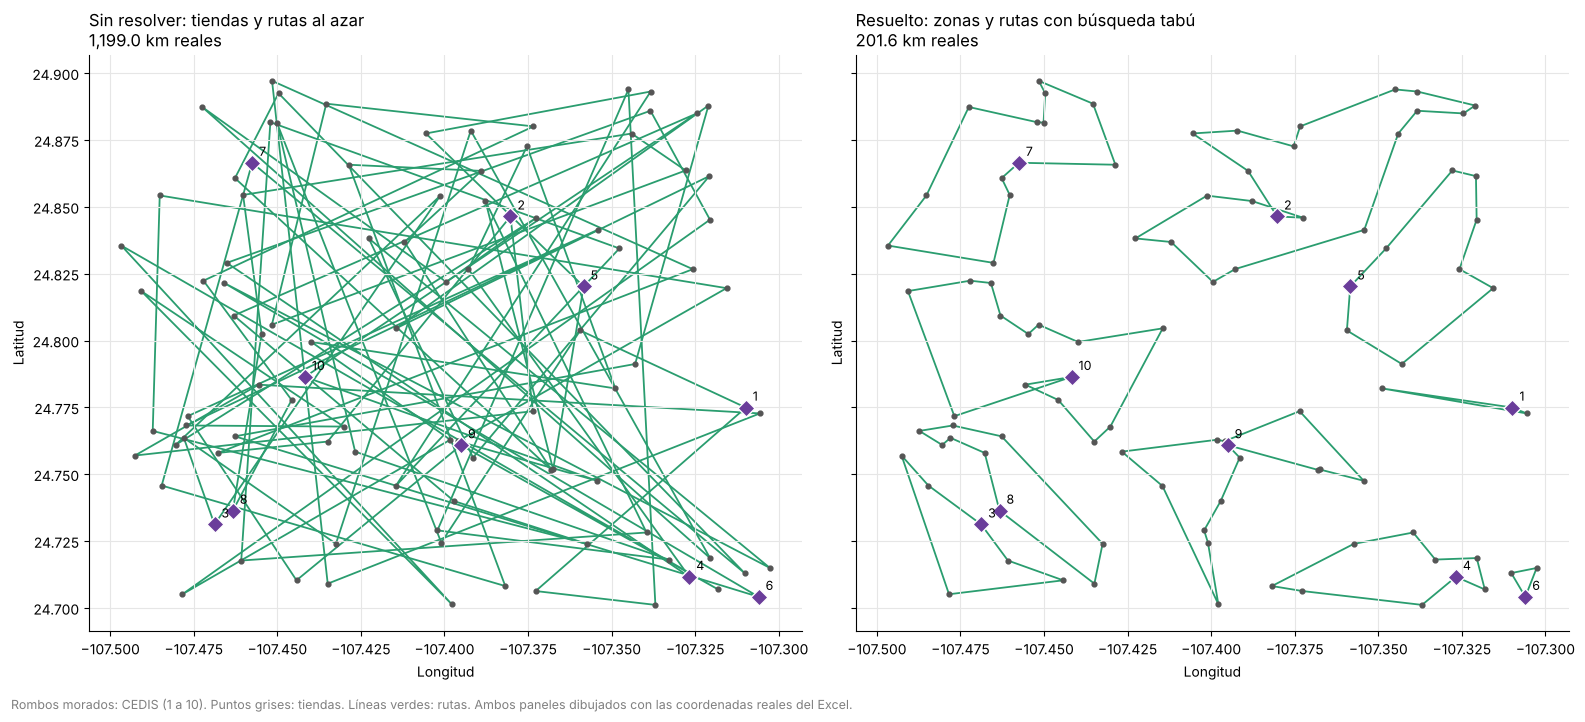

In [19]:
import matplotlib.pyplot as plt

def dibujar_rutas(ax, rutas, titulo, km_total):
    """Dibuja las rutas cerradas, las tiendas y los CEDIS sobre un panel."""
    # Líneas de cada ruta: CEDIS -> 9 tiendas -> CEDIS
    for c, ruta in rutas.items():
        secuencia = ruta + [ruta[0]]
        lons = [df_tiendas.loc[n, 'Longitud_WGS84'] for n in secuencia]
        lats = [df_tiendas.loc[n, 'Latitud_WGS84'] for n in secuencia]
        ax.plot(lons, lats, color='#2a9d6f', linewidth=1.3, zorder=1)

    # Tiendas (puntos grises) y CEDIS (rombos morados)
    ax.scatter(tiendas_df['Longitud_WGS84'], tiendas_df['Latitud_WGS84'], c='#555555', s=12, zorder=2)
    ax.scatter(cedis_df['Longitud_WGS84'], cedis_df['Latitud_WGS84'], c='#6a3d9a', marker='D', s=75, edgecolors='white', zorder=3)

    # Número de cada CEDIS
    for idx, row in cedis_df.iterrows():
        ax.annotate(str(idx + 1), (row['Longitud_WGS84'], row['Latitud_WGS84']),
                    xytext=(5, 5), textcoords='offset points', fontsize=9)

    ax.set_title(f'{titulo}\n{km_total:,.1f} km reales', loc='left', fontsize=12)
    ax.set_xlabel('Longitud')
    ax.set_ylabel('Latitud')
    ax.grid(True, color='#e6e6e6')
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
dibujar_rutas(ax1, rutas_sin_resolver, 'Sin resolver: tiendas y rutas al azar', km_sin_resolver)
dibujar_rutas(ax2, rutas_resueltas, 'Resuelto: zonas y rutas con búsqueda tabú', km_resueltas)

fig.text(0.01, -0.02, 'Rombos morados: CEDIS (1 a 10). Puntos grises: tiendas. Líneas verdes: rutas. '
         'Ambos paneles dibujados con las coordenadas reales del Excel.', fontsize=9, color='gray')
plt.tight_layout()
plt.savefig('./Datasets/comparativa_rutas.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusiones

- La búsqueda tabú redujo la distancia de 569.87 km a 269.81 km (52.65 %) y el combustible en la misma proporción.
- Fue 5.6 % mejor que el vecino más cercano y tardó menos de un segundo.
- Una lista tabú de 10 dio el mejor promedio; con listas muy pequeñas el algoritmo se cicla.
- Con coordenadas reales, la distancia bajó de 1,199.0 km (al azar) a 201.6 km.